# Adaptive Remeshing

Use adaptive remeshing to reduce element distortion. The approach follows the updated Lagrangian framework of [1], using fixed remeshing intervals. The deformation history is stored directly as one DG0 tensor per triangle and interpolated onto the new mesh.

## Reference

[1] S. Léger, *An updated Lagrangian method with error estimation and adaptive remeshing for very large deformation elasticity problems*, 2014

In [21]:
import gmsh
import dolfinx.fem.petsc
from mpi4py import MPI
import viskex
import pyvista as pv
import ufl
import numpy as np
from petsc4py import PETSc
from pathlib import Path
import shutil
from matplotlib import pyplot as plt
import xml.etree.ElementTree as ET
import h5py

rank = 0
comm = MPI.COMM_WORLD
pv.set_jupyter_backend("static")

# Results folder
results = Path("./results_remesh")
results.mkdir(exist_ok=True)

# Initial Mesh
gdim            = 2
WIDTH           = 1.0
HEIGHT          = 2.0
NX              = 10
NY              = 20
REMESH_H        = 0.1
REMESH_EVERY    = 50

# Material
mu = 3.0

# Iteration
steps   = 600
delta_u = 0.01
PRINT_EVERY = 10

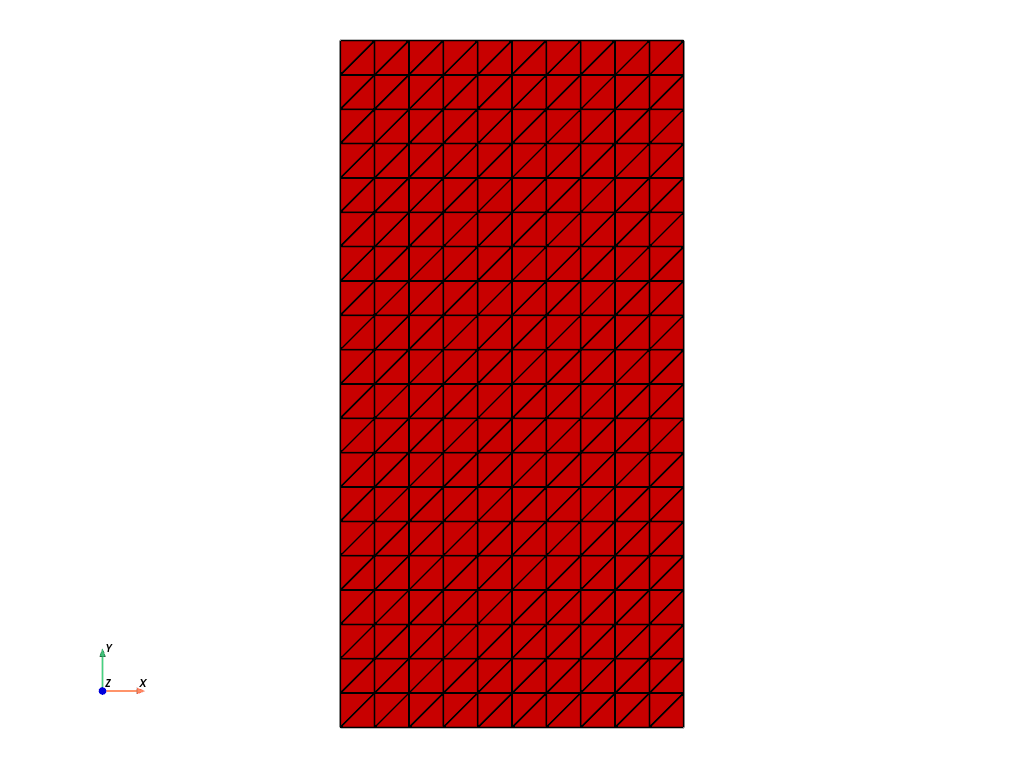

In [22]:
domain = dolfinx.mesh.create_rectangle(comm, 
                                       [(0,0), (WIDTH, HEIGHT)], 
                                       [NX, NY])
initial_mesh = domain.geometry.x.copy()
viskex.dolfinx.plot_mesh(domain)

V   = dolfinx.fem.functionspace(domain, ("Lagrange", 2, (gdim,)))
uh  = dolfinx.fem.Function(V)
v   = ufl.TestFunction(V)
du  = ufl.TrialFunction(V)

bottom_dofs = dolfinx.fem.locate_dofs_geometrical(V, lambda x: np.isclose(0.0, x[1]))
top_dofs    = dolfinx.fem.locate_dofs_geometrical(V, lambda x: np.isclose(HEIGHT, x[1]))

bs = V.dofmap.index_map_bs
reaction_bottom_dofs = (bs * bottom_dofs, bs * bottom_dofs + 1)

U = dolfinx.fem.Constant(domain, dolfinx.default_scalar_type([0.0, 0.0]))
bottom_bc = dolfinx.fem.dirichletbc(dolfinx.default_scalar_type([0.0, 0.0]), bottom_dofs, V)
top_bc    = dolfinx.fem.dirichletbc(U, top_dofs, V)
bcs = [bottom_bc, top_bc]

Step = 000
Step = 010
Step = 020
Step = 030
Step = 040
Step = 050
Step = 060
Step = 070
Step = 080
Step = 090
Step = 100
Step = 110
Step = 120
Step = 130
Step = 140
Step = 150
Step = 160
Step = 170
Step = 180
Step = 190
Step = 200
Step = 210
Step = 220
Step = 230
Step = 240
Step = 250
Step = 260
Step = 270
Step = 280
Step = 290
Step = 300
Step = 310
Step = 320
Step = 330
Step = 340
Step = 350
Step = 360
Step = 370
Step = 380
Step = 390
Step = 400
Step = 410
Step = 420
Step = 430
Step = 440
Step = 450
Step = 460
Step = 470
Step = 480
Step = 490
Step = 500
Step = 510
Step = 520
Step = 530
Step = 540
Step = 550
Step = 560
Step = 570
Step = 580
Step = 590
Step = 600


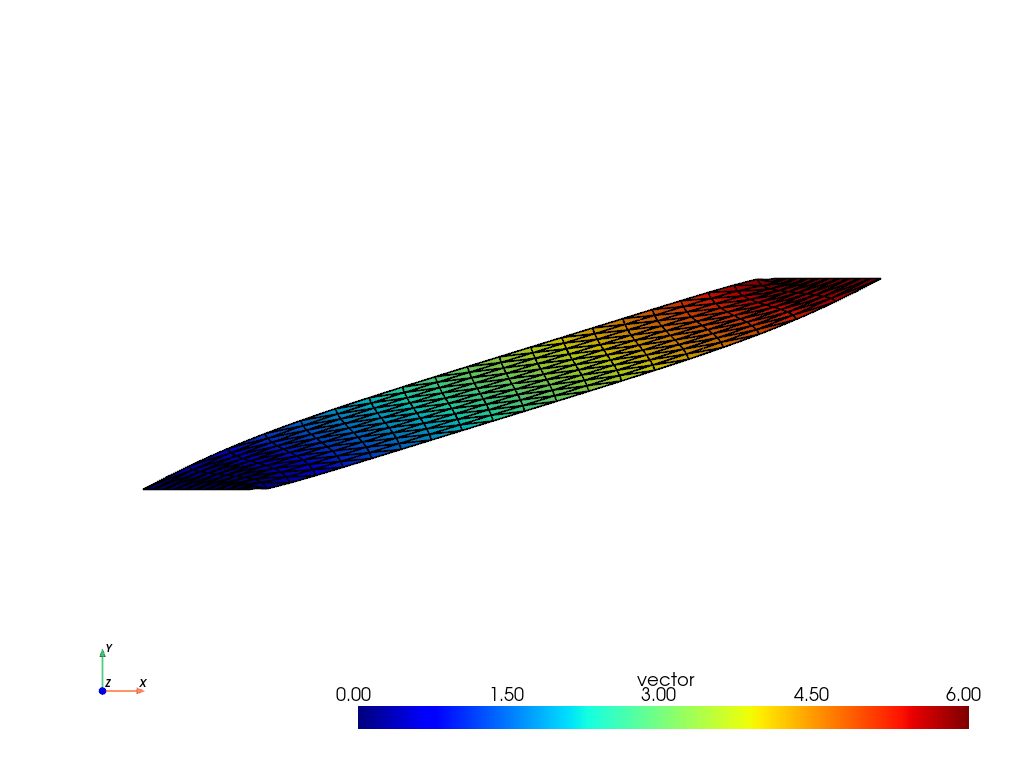

In [23]:
def triangle_quality(msh):
    cells = msh.topology.index_map(2).size_local
    triangles = np.asarray(msh.geometry.dofmaps[0][:cells, :3], dtype=np.int32)
    xyz = msh.geometry.x[:, :2]
    a, b, c = [xyz[triangles[:, j]] for j in range(3)]
    area2 = np.abs((b[:, 0]-a[:, 0])*(c[:, 1]-a[:, 1])
                   - (b[:, 1]-a[:, 1])*(c[:, 0]-a[:, 0]))
    edges2 = np.sum((b-a)**2, axis=1) + np.sum((c-b)**2, axis=1) + np.sum((a-c)**2, axis=1)
    return 2*np.sqrt(3)*area2 / edges2

def nodal_displacement(msh, u):
    W = dolfinx.fem.functionspace(msh, ("Lagrange", 1, (gdim,)))
    u_geom = dolfinx.fem.Function(W)
    u_geom.interpolate(u)

    disp = np.zeros((len(msh.geometry.x), gdim))
    values = u_geom.x.array.reshape(-1, gdim)
    for c in range(msh.topology.index_map(2).size_local):
        disp[msh.geometry.dofmaps[0][c]] = values[W.dofmap.cell_dofs(c)]
    return disp

class XDMFSeries:

    def __init__(self, filename):
        filename        = Path(filename)
        self.xdmf       = filename.with_suffix(".xdmf")
        self.h5_file    = filename.with_suffix(".h5")
        self.h5         = h5py.File(self.h5_file, "w")

        self.root       = ET.Element("Xdmf", Version="3.0")
        domain          = ET.SubElement(self.root, "Domain")
        self.collection = ET.SubElement(
            domain, "Grid",
            Name=filename.stem,
            GridType="Collection",
            CollectionType="Temporal"
        )

    def _data(self, parent, path, values, kind="Float"):
        values = np.asarray(values)
        self.h5.create_dataset(path, data=values)

        node = ET.SubElement(
            parent, "DataItem",
            Dimensions=" ".join(map(str, values.shape)),
            NumberType=kind,
            Precision="8",
            Format="HDF"
        )
        node.text = f"{self.h5_file.name}:{path}"

    def write(self, msh, u, step, t, cauchy_stress):
        group = f"/step_{step:03d}"
        if isinstance(cauchy_stress, dolfinx.fem.Function):
            space = cauchy_stress.function_space
            cells = msh.topology.index_map(2).size_local
            dofs = np.array([space.dofmap.cell_dofs(c)[0] for c in range(cells)],
                            dtype=np.int32)
            cauchy_stress = cauchy_stress.x.array.reshape(-1, 9)[dofs].copy()

        n_cells = msh.topology.index_map(2).size_local
        connectivity = np.asarray(
            msh.geometry.dofmaps[0][:n_cells], dtype=np.int64
        )
        n_nodes_cell = connectivity.shape[1]
        connectivity = connectivity[:, np.argsort(
            dolfinx.io.utils.cell_perm_vtk(dolfinx.mesh.CellType.triangle, n_nodes_cell)
        )]
        
        coords = np.asarray(msh.geometry.x, dtype=np.float64)

        displacement = np.zeros_like(coords)
        displacement[:, :2] = nodal_displacement(msh, u)

        quality = triangle_quality(msh)

        grid = ET.SubElement(
            self.collection, "Grid",
            Name=f"Step_{step:03d}",
            GridType="Uniform"
        )
        ET.SubElement(grid, "Time", Value=str(t))

        topology = ET.SubElement(
            grid, "Topology",
            TopologyType="Triangle_6" if n_nodes_cell == 6 else "Triangle",
            NumberOfElements=str(n_cells)
        )
        self._data(topology, group + "/triangle", connectivity, "Int")

        geometry = ET.SubElement(grid, "Geometry", GeometryType="XYZ")
        self._data(geometry, group + "/coordinates", coords)

        attribute = ET.SubElement(
            grid, "Attribute",
            Name="Displacement",
            AttributeType="Vector",
            Center="Node"
        )
        self._data(attribute, group + "/displacement", displacement)

        attribute = ET.SubElement(
            grid, "Attribute",
            Name="Element_Quality",
            AttributeType="Scalar",
            Center="Cell"
        )
        self._data(attribute, group + "/element_quality", quality)

        attribute = ET.SubElement(
            grid, "Attribute",
            Name="Cauchy_Stress",
            AttributeType="Tensor",
            Center="Cell"
        )
        self._data(attribute, group + "/cauchy_stress", cauchy_stress)

        self.h5.flush()

    def close(self):
        self.h5.close()
        ET.indent(self.root, space="  ")
        ET.ElementTree(self.root).write(
            self.xdmf, encoding="utf-8", xml_declaration=True
        )


I   = ufl.Identity(2)
F   = ufl.variable(I + ufl.grad(uh))
J2  = ufl.det(F)
lam = 1.0 / J2
psi = 0.5 * mu * (ufl.tr(F.T * F) + lam**2 - 3.0)
sigma_2d = mu * (F * F.T - lam**2 * I)
sigma = ufl.as_tensor([
    [sigma_2d[0, 0], sigma_2d[0, 1], 0.0],
    [sigma_2d[1, 0], sigma_2d[1, 1], 0.0],
    [0.0, 0.0, 0.0],
])
W_sigma = dolfinx.fem.functionspace(domain, ("DG", 0, (3, 3)))
stress = dolfinx.fem.Function(W_sigma)
stress_expr = dolfinx.fem.Expression(sigma, W_sigma.element.interpolation_points)

Pi  = psi * ufl.dx
R   = ufl.derivative(Pi, uh, v)
K   = ufl.derivative(R, uh, du)
residual = dolfinx.fem.form(R)
energy_form_ref = dolfinx.fem.form(
    psi * ufl.dx(metadata={"quadrature_degree": 8}))

problem = dolfinx.fem.petsc.NonlinearProblem(
    R,
    uh,
    bcs=bcs,
    J=K,
    petsc_options_prefix="remesh_",
    petsc_options={
        "snes_type": "newtonls",
        "snes_linesearch_type": "bt",
        "snes_rtol": 1e-9,
        "snes_atol": 1e-10,
        "snes_max_it": 50,
        "snes_error_if_not_converged": True,
        "ksp_type": "preonly",
        "pc_type": "lu",
    },
)

writer = XDMFSeries(results / "p2_noremesh")
u = np.linspace(0, steps*delta_u, steps+1)
fx_ref = np.zeros(steps+1)
fy_ref = np.zeros(steps+1)
q_ref  = np.zeros(steps+1)
energy_ref = np.zeros(steps+1)

for step, u_step in enumerate(u):
    U.value = dolfinx.default_scalar_type([u_step, 0.0])
    problem.solve()
    vec = dolfinx.fem.petsc.assemble_vector(residual)
    bottom_force = np.array([vec.array[dofs].sum()
                            for dofs in reaction_bottom_dofs])

    vec.destroy()
    fx_ref[step] = bottom_force[0]
    fy_ref[step] = bottom_force[1]

    energy_ref[step] = float(np.real(comm.allreduce(
        dolfinx.fem.assemble_scalar(energy_form_ref), op=MPI.SUM)))

    stress.interpolate(stress_expr)
    n_cells = domain.topology.index_map(2).size_local
    cell_dofs = np.array([W_sigma.dofmap.cell_dofs(c)[0] for c in range(n_cells)],
                         dtype=np.int32)
    cauchy_stress = stress.x.array.reshape(-1, 9)[cell_dofs].copy()

    disp = nodal_displacement(domain, uh)
    domain.geometry.x[:, :gdim] += disp
    writer.write(domain, uh, step, u_step, cauchy_stress)
    q_ref[step] = min(triangle_quality(domain))
    domain.geometry.x[:] = initial_mesh

    if step % PRINT_EVERY == 0:
        print(f"Step = {step:03d}")


writer.close()

viskex.dolfinx.plot_vector_field(uh, warp_factor=1.0)

Step = 010
Step = 020
Step = 030
Step = 040
Step = 050
Step = 060
Step = 070
Step = 080
Step = 090
Step = 100
Step = 110
Step = 120
Step = 130
Step = 140
Step = 150
Step = 160
Step = 170
Step = 180
Step = 190
Step = 200
Step = 210
Step = 220
Step = 230
Step = 240
Step = 250
Step = 260
Step = 270
Step = 280
Step = 290
Step = 300
Step = 310
Step = 320
Step = 330
Step = 340
Step = 350
Step = 360
Step = 370
Step = 380
Step = 390
Step = 400
Step = 410
Step = 420
Step = 430
Step = 440
Step = 450
Step = 460
Step = 470
Step = 480
Step = 490
Step = 500
Step = 510
Step = 520
Step = 530
Step = 540
Step = 550
Step = 560
Step = 570
Step = 580
Step = 590
Step = 600


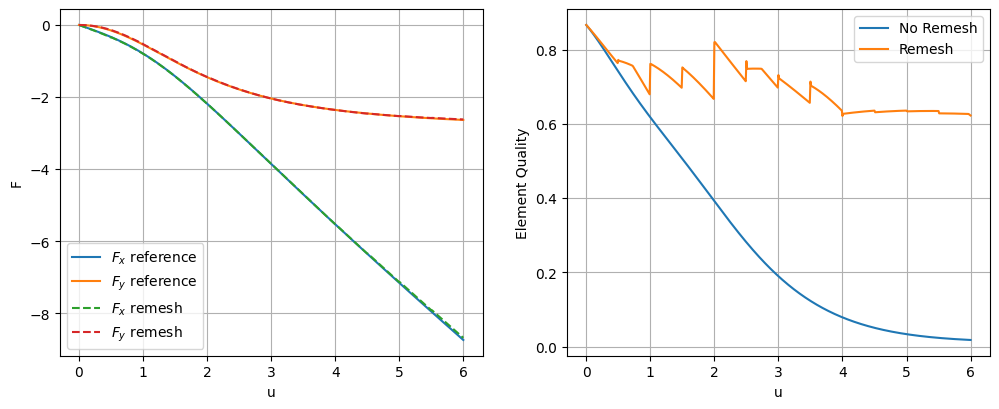

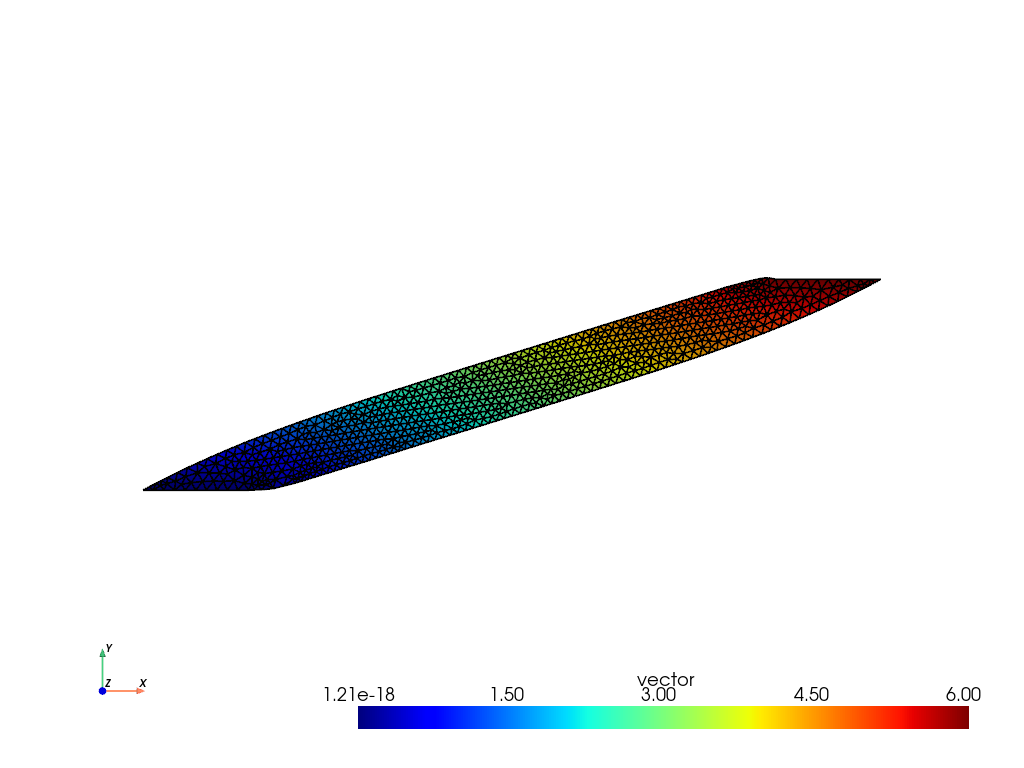

In [24]:
def boundary_polygon(msh):
    t = msh.topology
    t.create_connectivity(1, 0)
    t.create_connectivity(1, 2)
    edges = t.connectivity(1, 0)
    neighbors = {}
    for facet in dolfinx.mesh.exterior_facet_indices(t):
        a, b = map(int, edges.links(int(facet)))
        neighbors.setdefault(a, []).append(b)
        neighbors.setdefault(b, []).append(a)

    vertices = np.array(sorted(neighbors), dtype=np.int32)
    geom = dolfinx.mesh.entities_to_geometry(msh, 0, vertices).reshape(-1)
    xy = {int(v): msh.geometry.x[g, :2] for v, g in zip(vertices, geom)}
    start = min(neighbors, key=lambda v: (xy[v][1], xy[v][0]))

    order, previous, current = [start], None, start
    while True:
        following = next(v for v in neighbors[current] if v != previous)
        if following == start:
            break
        order.append(following)
        previous, current = current, following

    points = np.array([xy[v] for v in order])
    signed_area2 = np.sum(points[:, 0] * np.roll(points[:, 1], -1)
                          - np.roll(points[:, 0], -1) * points[:, 1])
    return points if signed_area2 > 0 else points[::-1]


def remesh_p1(old_mesh, step):
    polygon = boundary_polygon(old_mesh)
    gmsh.initialize()
    try:
        gmsh.option.setNumber("General.Terminal", 0)
        gmsh.model.add(f"remesh_{step:03d}")
        gmsh.option.setNumber("Mesh.MeshSizeFromPoints", 0)
        gmsh.option.setNumber("Mesh.MeshSizeMin", REMESH_H)
        gmsh.option.setNumber("Mesh.MeshSizeMax", REMESH_H)
        geo = gmsh.model.geo
        p = [geo.addPoint(float(x), float(y), 0, REMESH_H) for x, y in polygon]
        lines = [geo.addLine(p[i], p[(i+1) % len(p)]) for i in range(len(p))]
        surface = geo.addPlaneSurface([geo.addCurveLoop(lines)])
        geo.synchronize()
        gmsh.model.addPhysicalGroup(2, [surface])
        gmsh.model.mesh.generate(2)
        data = dolfinx.io.gmsh.model_to_mesh(gmsh.model, comm, 0, gdim=2)
        return data.mesh if hasattr(data, "mesh") else data[0]
    finally:
        gmsh.finalize()

def transfer_field(old_F, new_F):
    new_mesh = new_F.function_space.mesh
    cells = np.arange(new_mesh.topology.index_map(2).size_local, dtype=np.int32)
    info = dolfinx.fem.create_interpolation_data(
        new_F.function_space, old_F.function_space, cells, padding=1e-8)
    new_F.interpolate_nonmatching(old_F, cells, info, tol=1e-12, maxit=30)

class MechanicalState:

    def __init__(self, msh, previous=None):

        self.msh    = msh
        self.step   = 0 if previous is None else previous.step

        self.V = dolfinx.fem.functionspace(msh, ("Lagrange", 1, (gdim,)))
        self.Q = dolfinx.fem.functionspace(msh, ("DG", 0, (gdim, gdim)))
        self.du         = dolfinx.fem.Function(self.V)
        self.u_total    = dolfinx.fem.Function(self.V)
        self.F_hist     = dolfinx.fem.Function(self.Q)

        if previous is None:
            self.F_hist.interpolate(
                lambda x: np.tile(np.eye(2).reshape(4, 1), (1, x.shape[1])))

        else:
            transfer_field(previous.F_hist, self.F_hist)
            transfer_field(previous.u_total, self.u_total)

        self.W_sigma        = dolfinx.fem.functionspace(msh, ("DG", 0, (3, 3)))
        self.cauchy_stress  = dolfinx.fem.Function(self.W_sigma, name="Cauchy_Stress")
        self._update_cauchy_stress()

        msh.topology.create_connectivity(1, 2)
        fd = msh.topology.dim - 1
        bottom_facets = dolfinx.mesh.locate_entities_boundary(
            msh, fd, lambda x: np.isclose(x[1], 0, atol=1e-10))
        top_facets = dolfinx.mesh.locate_entities_boundary(
            msh, fd, lambda x: np.isclose(x[1], HEIGHT, atol=1e-10, rtol=0))
        bottom_dofs = dolfinx.fem.locate_dofs_topological(self.V, fd, bottom_facets)
        top_x = dolfinx.fem.locate_dofs_topological(self.V.sub(0), fd, top_facets)
        top_y_dofs = dolfinx.fem.locate_dofs_topological(self.V.sub(1), fd, top_facets)
        bs = self.V.dofmap.index_map_bs
        self.reaction_bottom_dofs = (bs*bottom_dofs, bs*bottom_dofs + 1)
        self.load_x = dolfinx.fem.Constant(msh, dolfinx.default_scalar_type(delta_u))
        bcs = [
            dolfinx.fem.dirichletbc(np.array([0., 0.], dtype=dolfinx.default_scalar_type), bottom_dofs, self.V),
            dolfinx.fem.dirichletbc(self.load_x, top_x, self.V.sub(0)),
            dolfinx.fem.dirichletbc(dolfinx.default_scalar_type(0.0), top_y_dofs, self.V.sub(1))
        ]

        F_inc   = ufl.Identity(2) + ufl.grad(self.du)
        F_new   = ufl.dot(F_inc, self.F_hist)
        J       = ufl.det(F_new)
        J_hist  = ufl.det(self.F_hist)

        psi0                = 0.5*mu*(ufl.inner(F_new, F_new) + J**(-2) - 3)
        dx_n                = ufl.Measure("dx", domain=msh)
        energy              = (psi0 / J_hist)*dx_n
        psi_hist            = 0.5*mu*(ufl.inner(self.F_hist, self.F_hist) + J_hist**(-2) - 3)
        self.energy_form    = dolfinx.fem.form((psi_hist / J_hist)*dx_n)
        v, w                = ufl.TestFunction(self.V), ufl.TrialFunction(self.V)
        R                   = ufl.derivative(energy, self.du, v)
        jacobian            = ufl.derivative(R, self.du, w)
        self.residual       = dolfinx.fem.form(R)

        self.problem = dolfinx.fem.petsc.NonlinearProblem(
            R, self.du, bcs=bcs, J=jacobian,
            petsc_options_prefix=f"remesh_",
            petsc_options={
                "snes_type": "newtonls", "snes_linesearch_type": "bt",
                "snes_atol": 1e-9, "snes_rtol": 1e-9, "snes_max_it": 50,
                "snes_error_if_not_converged": True,
                "ksp_type": "preonly", "pc_type": "lu",
                "ksp_error_if_not_converged": True,
            })
        
        self.F_next = dolfinx.fem.Function(self.Q)
        self.F_expr = dolfinx.fem.Expression(F_new, self.Q.element.interpolation_points)

    def internal_energy(self):
        local_energy = dolfinx.fem.assemble_scalar(self.energy_form)
        return float(np.real(self.msh.comm.allreduce(local_energy, op=MPI.SUM)))

    def _update_cauchy_stress(self):
        history = self.F_hist.x.array.reshape(-1, gdim, gdim)
        values = self.cauchy_stress.x.array.reshape(-1, 3, 3)
        values[:] = 0.0
        for c in range(self.msh.topology.index_map(2).size_local):
            F = history[self.Q.dofmap.cell_dofs(c)[0]]
            J = np.linalg.det(F)
            dof = self.W_sigma.dofmap.cell_dofs(c)[0]
            values[dof, :2, :2] = mu * (F @ F.T - J**(-2) * np.eye(2))

    def advance(self):
        self.problem.solve()
        fx, fy = self._reactions()
        self.F_next.interpolate(self.F_expr)
        self.msh.geometry.x[:, :gdim] += nodal_displacement(self.msh, self.du)
        self.u_total.x.array[:] += self.du.x.array
        self.F_hist.x.array[:] = self.F_next.x.array
        self._update_cauchy_stress()
        self.step += 1
        return fx, fy

    def _reactions(self):
        vec = dolfinx.fem.petsc.assemble_vector(self.residual)
        bottom = np.array([vec.array[dofs].sum() for dofs in self.reaction_bottom_dofs])
        vec.destroy()
        return float(bottom[0]), float(bottom[1])


remesh_domain = dolfinx.mesh.create_rectangle(
    comm, [(0, 0), (WIDTH, HEIGHT)], [NX, NY])
state = MechanicalState(remesh_domain)
writer = XDMFSeries(results / "p1_remesh")
writer.write(state.msh, state.u_total, state.step, 0.0, state.cauchy_stress)
fx_remesh = np.zeros(steps+1)
fy_remesh = np.zeros(steps+1)
q_remesh = np.zeros(steps+1)
q_remesh[0] = min(triangle_quality(state.msh))
energy_remesh = np.zeros(steps+1)
energy_remesh[0] = state.internal_energy()
for step in range(1, steps+1):
    fx, fy = state.advance()

    is_remesh = step % REMESH_EVERY == 0 and step < steps
    if is_remesh:
        new_mesh = remesh_p1(state.msh, step)
        state = MechanicalState(new_mesh, previous=state)

    fx_remesh[step], fy_remesh[step] = fx, fy
    q_remesh[step] = min(triangle_quality(state.msh))
    energy_remesh[step] = state.internal_energy()
    writer.write(state.msh, state.u_total, step, step*delta_u, state.cauchy_stress)

    if step % PRINT_EVERY == 0:
        print(f"Step = {step:03d}")

writer.close()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(u, fx_ref, label=r"$F_x$ reference")
axes[0].plot(u, fy_ref, label=r"$F_y$ reference")
axes[0].plot(u, fx_remesh, "--", label=r"$F_x$ remesh")
axes[0].plot(u, fy_remesh, "--", label=r"$F_y$ remesh")
axes[0].set_ylabel("F")
axes[1].plot(u, q_ref, label="No Remesh")
axes[1].plot(u, q_remesh, label="Remesh")
axes[1].set_ylabel("Element Quality")
for ax in axes:
    ax.set_xlabel("u")
    ax.grid(True)
    ax.legend()
plt.show()

viskex.dolfinx.plot_vector_field(state.u_total, warp_factor=0.0)

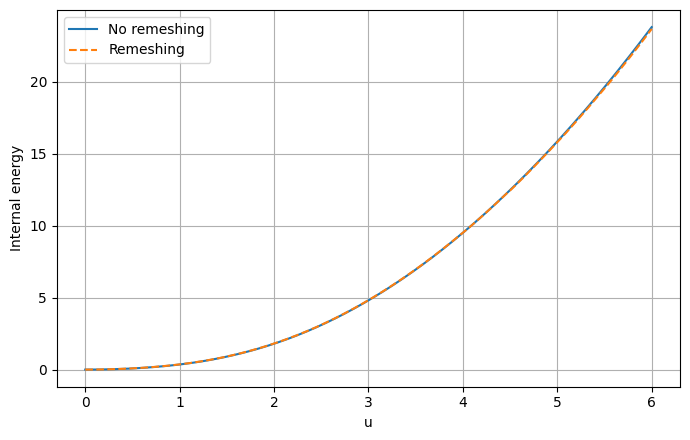

In [25]:
fig_energy, ax_energy = plt.subplots(figsize=(7, 4.5))
ax_energy.plot(u, energy_ref, label="No remeshing")
ax_energy.plot(u, energy_remesh, "--", label="Remeshing")
ax_energy.set_xlabel("u")
ax_energy.set_ylabel("Internal energy")
ax_energy.grid(True)
ax_energy.legend()
fig_energy.tight_layout()
plt.show()
